# Neighborhoods near MSU

This project helps international families compare housing, schools, and recorded crime near MSU. One row is one Census block group. I use local extracts for 172 block groups near Lansing, East Lansing, Okemos, and Haslett. At least 70% of each block group is within 10 km of MSU Main Library. 

The files in `data/input` are the starting data for this project. Source names and dates are in README.md.

In [1]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from prepare import DATA, ensure_data, print_progress
from housing import METRICS, PROFILE, PEOPLE
from IPython.display import display

ensure_data(print_progress)
bg = gpd.read_file(DATA / 'processed/neighborhoods.geojson')
summary = pd.read_csv(DATA / 'processed/summary.csv')
correlations = pd.read_csv(DATA / 'processed/correlations.csv', index_col='variable')
print(f'{len(bg)} block groups, {bg.GEOID.nunique()} unique GEOIDs')

plt.style.use('default')
city_colors = dict(zip(['East Lansing', 'Lansing', 'Okemos', 'Haslett'], sns.color_palette('Set2', 4)))


Preprocessing: cached (0.00s)
Analysis: cached (0.00s)
172 block groups, 172 unique GEOIDs


## Data checks

Check missing values and duplicate block-group IDs. Missing crime data do not mean zero crime. For crime comparisons, only Lansing and East Lansing are used because Okemos and Haslett have incomplete coverage.

In [2]:
# Check available and missing values for each variable, including population characteristics.
labels = {}
for name, (column, unit) in METRICS.items():
    labels[column] = name
for name, (column, unit, lower_is_better) in PROFILE.items():
    labels[column] = name
for name, column in PEOPLE.items():
    labels[column] = name

rows = []
for column, name in labels.items():
    rows.append({
        'variable': name,
        'available': bg[column].count(),
        'missing': bg[column].isna().sum(),
    })
checks = pd.DataFrame(rows)
display(checks)
display(bg.groupby('area_name').crime_coverage.value_counts().rename('block_groups').to_frame())
print('Duplicate GEOIDs:', bg.GEOID.duplicated().sum())

,variable,available,missing
0,Monthly rent,118,54
1,Home value,140,32
2,Household income,148,24
3,Households with someone under 18,163,9
4,Bachelor's+ (adults 25+),169,3
5,Vacant housing,164,8
6,Renter households,163,9
7,Poverty,163,9
8,Distance to MSU,172,0
9,Nearest public school,172,0


block_groups
area_name    crime_coverage                    
East Lansing Within provider city            30
             Partial city overlap            10
Haslett      Unavailable                     11
             Partial city overlap             2
Lansing      Within provider city            84
             Partial city overlap            17
Okemos       Unavailable                     14
             Partial city overlap             4

Duplicate GEOIDs: 0


## Block-group population

The study has 172 block groups. The chart shows their ACS 2020–2024 population estimates, including groups with an estimate of zero. These are area estimates, not the number of survey respondents.

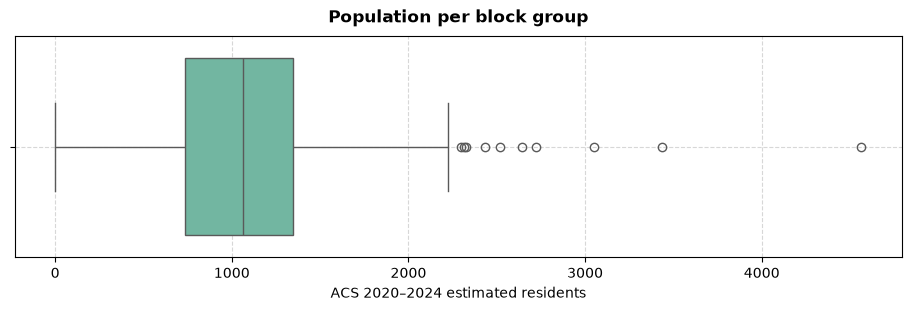

,Available groups,Minimum,Median,Maximum
0,172,0.0,1062.5,4564.0


In [3]:
# Block-group population sizes differ, which matters when interpreting record counts.
# Keep zero population estimates; they are not missing values.
population = bg['Tot_Population_ACS_20_24'].dropna()
fig, ax = plt.subplots(figsize=(9, 3), layout='constrained')
sns.boxplot(x=population, color=sns.color_palette('Set2')[0], ax=ax)
ax.set_title('Population per block group', fontsize=12, fontweight='bold', pad=10)
ax.set_xlabel('ACS 2020–2024 estimated residents')
ax.grid(True, linestyle='--', alpha=.5)
plt.show()
display(pd.DataFrame({'Available groups': [len(population)], 'Minimum': [population.min()],
                      'Median': [population.median()], 'Maximum': [population.max()]}))

## Analysis 1

How are median gross rent and the share of households with children under 18 related to other variables?

Each observation is a block group. Pearson correlations use available pairs, not rows with every variable present.

**Crime coverage:** Only Lansing and East Lansing are included in crime comparisons. Okemos and Haslett are treated as N/A because their police data coverage is incomplete. N/A does not mean zero crime.

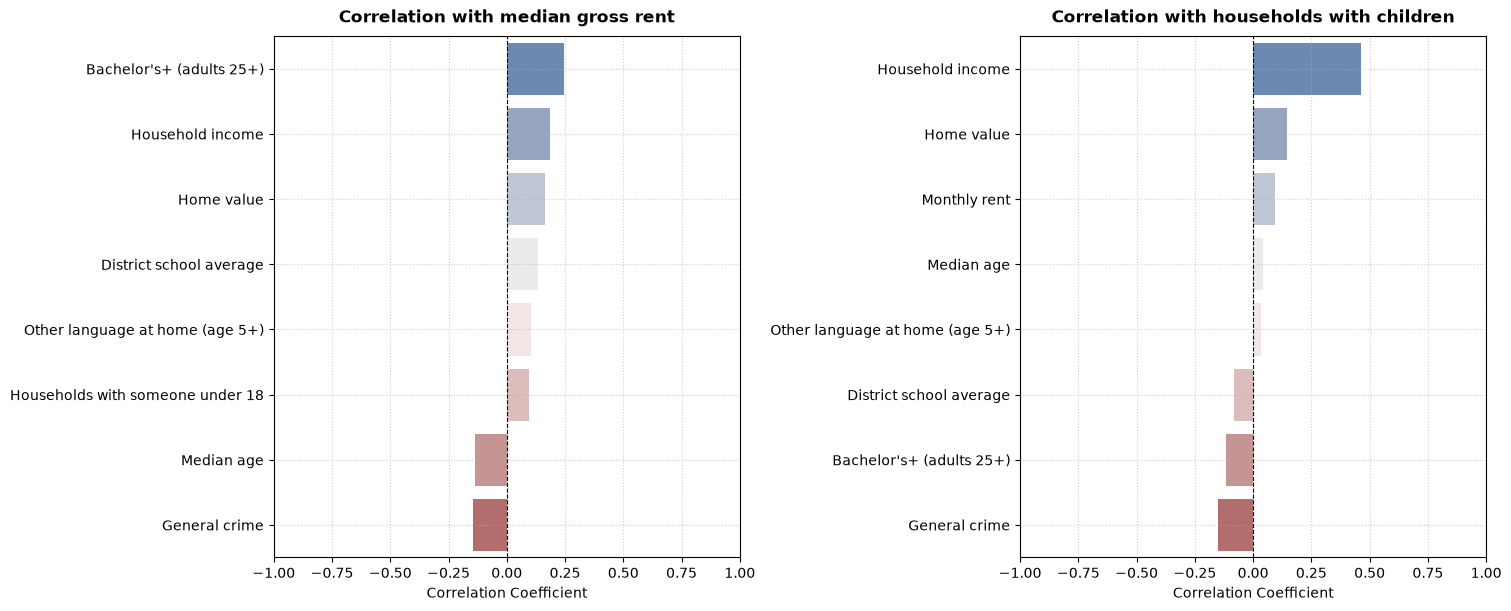

In [4]:
audit_df = bg.copy()
audit_df.loc[audit_df.area_name.isin(['Okemos', 'Haslett']), 'general_crime_count'] = float('nan')
question_columns = [
    'Med_Gross_Rent_ACS_20_24', 'Med_House_Value_BG_ACS_20_24',
    'Med_HHD_Inc_BG_ACS_20_24', 'pct_College_ACS_20_24',
    'pct_HHD_PPL_Und_18_ACS_20_24', 'Median_Age_ACS_20_24',
    'pct_Othr_Lang_ACS_20_24', 'general_crime_count', 'district_overall_mean'
]
labels['Median_Age_ACS_20_24'] = 'Median age'
corr_matrix = audit_df[question_columns].corr()
rent = 'Med_Gross_Rent_ACS_20_24'
children = 'pct_HHD_PPL_Und_18_ACS_20_24'
rent_corr = corr_matrix[rent].drop(rent).sort_values(ascending=False)
child_corr = corr_matrix[children].drop(children).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout='constrained')
for ax, values, title in zip(axes, [rent_corr, child_corr],
        ['Correlation with median gross rent', 'Correlation with households with children']):
    names = [labels[col] for col in values.index]
    sns.barplot(x=values.values, y=names, hue=names, palette='vlag',
                dodge=False, legend=False, ax=ax)
    ax.axvline(0, color='black', linestyle='--', linewidth=.8)
    ax.set_xlim(-1, 1)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel('Correlation Coefficient', fontsize=10)
    ax.grid(True, linestyle=':', alpha=.6)
plt.show()


**Interpretation**

**Rent:** Median rent has weak positive correlations with adult education, household income and home value.

**Households with children:** Their share has the strongest positive correlation with household income (r = 0.464) among the variables examined, and a weak negative correlation with recorded crime in Lansing and East Lansing. The income relationship may reflect household structure, such as two-earner couples; these data cannot confirm this.


## Analysis 2

How do child-household share, rent, school scores and recorded crime differ across the four areas?

**Crime is shown only for East Lansing and Lansing. Okemos and Haslett are N/A in this comparison, not zero.** These are counts of published records for April 10–October 6, 2026, not population-adjusted rates.

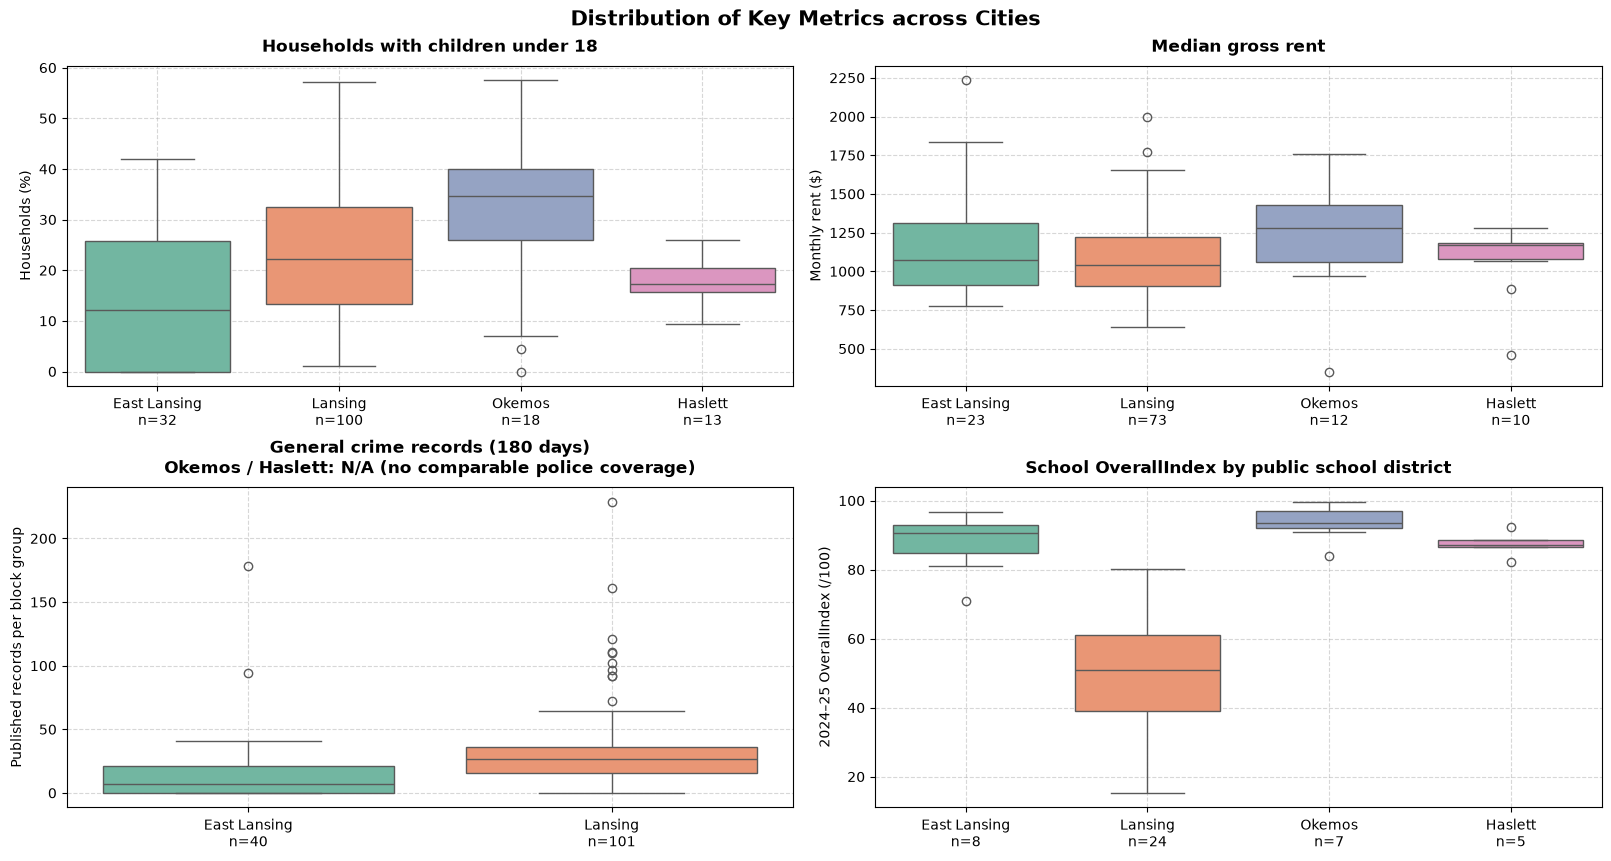

General crime: Okemos and Haslett are N/A in this analysis.


In [5]:
cities = ['East Lansing', 'Lansing', 'Okemos', 'Haslett']
police_cities = ['East Lansing', 'Lansing']
fig, axes = plt.subplots(2, 2, figsize=(16, 8.5), layout='constrained')
axes = axes.flatten()

for ax, col, title, unit in zip(axes[:3],
        [children, rent, 'general_crime_count'],
        ['Households with children under 18', 'Median gross rent', 'General crime records (180 days)'],
        ['Households (%)', 'Monthly rent ($)', 'Published records per block group']):
    order = police_cities if col == 'general_crime_count' else cities
    samples = [audit_df.loc[audit_df.area_name.eq(city), col].dropna() for city in order]
    sns.boxplot(data=audit_df, x='area_name', y=col, order=order,
                hue='area_name', palette=city_colors, legend=False, ax=ax)
    ax.set_xticks(range(len(order)), [f'{city}\nn={len(sample)}' for city, sample in zip(order, samples)])
    ax.set_xlabel('')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_ylabel(unit)
    ax.grid(True, linestyle='--', alpha=.5)
    if col == 'general_crime_count':
        ax.set_title(title + '\nOkemos / Haslett: N/A (no comparable police coverage)', fontsize=12, fontweight='bold', pad=10)

schools = pd.read_csv(DATA / 'input/schools.csv')
district_cities = {
    'East Lansing School District': 'East Lansing',
    'Lansing Public School District': 'Lansing',
    'Okemos Public Schools': 'Okemos',
    'Haslett Public Schools': 'Haslett'
}
schools['comparison_city'] = schools.operating_district.map(district_cities)
school_samples = [schools.loc[schools.comparison_city.eq(city), 'school_index'].dropna() for city in cities]
sns.boxplot(data=schools, x='comparison_city', y='school_index', order=cities,
            hue='comparison_city', palette=city_colors, legend=False, ax=axes[3])
axes[3].set_xticks(range(4), [f'{city}\nn={len(sample)}' for city, sample in zip(cities, school_samples)])
axes[3].set_xlabel('')
axes[3].set_title('School OverallIndex by public school district',
                  fontsize=12, fontweight='bold', pad=10)
axes[3].set_ylabel('2024–25 OverallIndex (/100)')
axes[3].grid(True, linestyle='--', alpha=.5)
fig.suptitle('Distribution of Key Metrics across Cities', fontsize=15, fontweight='bold')
plt.show()
print('General crime: Okemos and Haslett are N/A in this analysis.')

**interpretation**

Okemos has the highest mean child-household share, followed by Lansing, Haslett and East Lansing. Mean rent is highest in Okemos, but many rent estimates are missing. Lansing has a higher mean published police count than East Lansing, with several high-count block groups. Okemos and Haslett cannot be compared on crime with these data. School scores are generally higher in Okemos, East Lansing and Haslett. Lansing has lower scores and greater variation across schools. The school panel compares individual schools, while the other panels compare block groups.

The results describe the selected study-area block groups, not every neighborhood in each city. Areas differ in population, size and coverage. Schools and district boundaries do not guarantee enrollment.

## Run the map

```bash
streamlit run app.py
```

The app prepares missing or outdated results, shows the current stage, and then opens the map. It uses saved results when no new calculation is needed.